# Program 17: buffer purge and head reset, the simple fixes

**What:** on each unlearn request, run unlearning, delete the class from the buffer, and reset its row in the classifier head.

**How:** run BadTeacher (program 09) on the class's samples, then remove them from the buffer, along with their stored logits. Set that class's head weights to a fresh random init and keep it frozen. Run the full stream and measure all four metrics plus the probe.

**Why:** this is the honest baseline for your method. If these simple fixes already solve relapse, the guard is not needed, so you must measure them first.

**Understanding note:** these steps fix relapse through the buffer and at the output. They do nothing about the features slowly rebuilding the class, which the probe will reveal.

**Done when:** output-level relapse drops compared with program 12, but probe accuracy for forgotten classes still rises during later learning.

## Where this fits (for a first-time reader)

Phase D found:
- **12–13:** a forgotten task jumps back up at the very next learning step (task-IL 45% → 70%).
- **14:** the features of forgotten tasks stay almost as good as a model that never learned them, so the **head** is what forgets and what comes back.
- **15:** wolf images left in the buffer bring wolf back (+62 points). Deleting them is essential.

Before building our own method we test the **simple fixes**. If they already stop relapse, there is nothing left for Relapse-Guard to do.

On every `U` request, in this order:

| Step | What | Which relapse route it closes |
|---|---|---|
| BadTeacher | as in program 12 | (the unlearning itself) |
| **purge** | delete the forgotten classes' images (and their stored logits) from the buffer | buffer leakage (program 15) |
| **head reset** | the forgotten classes' rows of the head get fresh random weights and are **frozen**, so no later training can change them | output relapse: the head can't relearn to answer those classes |
| **logit mask** | DER++ keeps replaying *stored logits* of the other buffer images, which still contain values for the forgotten classes ("carriers", program 12). Those columns are left out of the replay loss. | the hidden route through stored logits |

**One change to unlearning, found while preparing Phase E.** BadTeacher pushes the forgotten classes' outputs towards a random network's, which is almost **uniform**. So the forgotten classes' scores end up nearly tied, and tiny leftovers in the features decide the winner. A test on wolf showed its accuracy falling to 40%, then **climbing back to 60–70% during unlearning itself**, even with 4× more steps or all 500 wolf images. More BadTeacher steps don't fix this; the head reset does. We also give BadTeacher all the training images of the forgotten item (a deletion request comes with its data) instead of only the buffer's few, and the bad teacher is now also checked *inside the task* (`common/badteacher.py`).

All Phase E programs use one shared runner, `common/clu.py`. Each run is one config (a dict of switches), and every result is saved under its name in `results/`, so later programs can reload it.

## 1. Setup

Two runs on program 12's stream `task15_seed0`, identical except for the fixes:
- `17_badteacher_only`: BadTeacher + purge (program 12, with the improved unlearning data);
- `17_simple_fixes`: + head reset + logit mask.

Program 12's own run is shown too, for reference. The **retrain** number (program 14) is the probe accuracy a model that never learned the forgotten tasks gets on them: the target for "really forgotten".

**Time:** about 15 minutes per run. A run that was already saved with the same config is loaded instead.

In [1]:
import gc, json, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.derpp, common.badteacher, common.features, common.metrics, common.stream, common.clu
for module in (common.utils, common.data, common.models, common.derpp, common.badteacher, common.features, common.metrics, common.stream, common.clu):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np

from common.clu import load_result, make_config, run_or_load
from common.data import SplitCIFAR100
from common.metrics import all_metrics, item_view
from common.utils import RESULTS_DIR, log_run

# Program 14's retrain model: probe accuracy on each task when the task was NEVER learned (the target).
RETRAIN_PROBE = None
for line in (RESULTS_DIR / "runs.jsonl").read_text().splitlines():
    entry = json.loads(line)
    if entry["program"] == "14_feature_probe":
        RETRAIN_PROBE = np.array(entry["results"]["probe"]["retrain"])

def metrics_row(res, kind="til"):
    s = res["summary"][kind]
    return s["RA"], s["FA"], s["Spill"], s["Relapse"]


def show_table(runs, retrain_probe=None):
    """runs: name -> result dict. Prints the four metrics and the probe numbers on forgotten items."""
    print(f"{'run':>28} | {'RA':>6} {'FA':>6} {'Spill':>6} {'Relapse':>7} | {'RA cil':>6} {'FA cil':>6} | "
          f"{'probe: before':>13} {'after U':>8} {'end':>6} {'peak rise':>9}")
    for name, res in runs.items():
        ra, fa, sp, rel = metrics_row(res, "til")
        rac, fac, _, _ = metrics_row(res, "cil")
        p = res["summary"].get("probe")
        ptxt = (f"{p['before']*100:12.1f}% {p['after_U']*100:7.1f}% {p['end']*100:5.1f}% {p['peak_rise']*100:+8.1f}"
                if p else f"{'-':>13} {'-':>8} {'-':>6} {'-':>9}")
        print(f"{name:>28} | {ra*100:5.1f}% {fa*100:5.1f}% {sp*100:6.1f} {rel*100:7.1f} | {rac*100:5.1f}% {fac*100:5.1f}% | {ptxt}")
    if retrain_probe is not None:
        print(f"\nretrain model (program 14), probe on the same forgotten tasks: {retrain_probe*100:.1f}%  (the target)")
    print("RA/FA/Spill/Relapse: task-IL (chance 10%); 'cil' = class-IL. Probe: 10-way on each forgotten task's features.")


def plot_forgotten(runs, title, file, show_retrain=True):
    """Head task-IL accuracy and feature probe of the forgotten items after every request."""
    import warnings
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
    for name, res in runs.items():
        acc, learned, forgotten, rows = item_view(res, "til")
        head = [np.nanmean(acc[r, forgotten[r]]) * 100 if forgotten[r].any() else np.nan for r in range(len(acc))]
        line, = axes[0].plot(head, marker="o", ms=3, label=name)
        if "probe" in res:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                axes[1].plot(np.nanmean(res["probe"], axis=1) * 100, marker="o", ms=3, color=line.get_color(), label=name)
    labels = [str(s) for s in next(iter(runs.values()))["requests"]]
    for ax in axes:
        ax.set_xticks(range(len(labels)), labels, rotation=45, fontsize=8)
    axes[0].axhline(10, color="gray", ls="--", lw=1, label="chance")
    axes[0].set(title="Head: task-IL accuracy of forgotten tasks (average, %)", ylabel="accuracy (%)", ylim=(0, 100))
    axes[1].set(title="Features: probe accuracy of forgotten tasks (average, %)", ylabel="probe accuracy (%)")
    if show_retrain and RETRAIN_PROBE is not None:
        axes[1].axhline(RETRAIN_PROBE[[int(s[1:]) for s in labels if s[0] == "U"]].mean() * 100,
                        color="green", ls=":", lw=1.5, label="retrain (target)")
    for ax in axes:
        ax.legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / file, dpi=120)
    plt.show()

RUNS = {
    "17_badteacher_only": make_config(name="17_badteacher_only", stream="task15_seed0"),
    "17_simple_fixes": make_config(name="17_simple_fixes", stream="task15_seed0",
                                   head_reset=True, mask_forgotten_logits=True),
}
SETTINGS = {name: cfg for name, cfg in RUNS.items()}
print(json.dumps(RUNS["17_simple_fixes"], indent=1))

{
 "name": "17_simple_fixes",
 "stream": "task15_seed0",
 "seed": 0,
 "workers": 2,
 "epochs": 5,
 "lr": 0.03,
 "batch_size": 32,
 "buffer_size": 2000,
 "replay_batch": 32,
 "alpha": 0.5,
 "beta": 0.5,
 "unlearn_lr": 0.0001,
 "unlearn_steps": 50,
 "forget_batch": 64,
 "retain_batch": 192,
 "forget_data": "all",
 "min_forget": 64,
 "bad_teacher_seed": 0,
 "purge_buffer": true,
 "head_reset": true,
 "mask_forgotten_logits": true,
 "guard": "none",
 "guard_lambda": 1.0,
 "k": 5,
 "signature": "specific",
 "signature_images": 1000,
 "probe_folds": 5
}


## 2. Run both

Each line is one request: `kept` = task-IL accuracy of kept tasks, `forgot head` = task-IL accuracy of forgotten tasks (chance 10%), `probe` = the feature probe on forgotten tasks.

In [2]:
data = SplitCIFAR100(seed=0, batch_size=32, num_workers=2)
results = {}
for name, cfg in RUNS.items():
    print(f"===== {name}")
    results[name] = run_or_load(cfg, data)
del data
gc.collect()

===== 17_badteacher_only


[  0] L5   kept  65.9%  train acc 65.3%  (77s)


[  1] L2   kept  72.2%  train acc 78.6%  (155s)


[  2] L3   kept  76.4%  train acc 73.7%  (230s)


[  3] L4   kept  76.5%  train acc 82.4%  (306s)


[  4] U5   kept  77.3%  forgot head  57.1%  probe  72.3%  forget imgs 5000 (494 in buffer), deleted 494  (334s)


... (23 outputs left out)

[ 12] L6   kept  79.4%  forgot head  13.6%  probe  76.2%  train acc 89.4%  (816s)


[ 13] L1   kept  80.5%  forgot head  13.4%  probe  76.5%  train acc 93.3%  (896s)


[ 14] U4   kept  76.9%  forgot head  11.7%  probe  76.1%  forget imgs 5000 (199 in buffer), deleted 199  (924s)


0

## 3. The four metrics and the probe

Columns: RA, FA, Spill, Relapse (task-IL, program 13), then class-IL RA/FA, then the probe on forgotten tasks: **before** `U`, right **after** `U`, at the **end**, and the **peak rise** (highest value after `U` minus the value right after `U`, i.e. how much the features came back at their worst).

In [3]:
runs = {}
p12 = RESULTS_DIR / "12_task15_seed0.npz"
if p12.exists():
    d = np.load(p12)
    r12 = {k: d[k] for k in d.files}
    r12["level"] = str(r12["level"])
    r12["summary"] = {}
    for kind in ("til", "cil"):
        acc, learned, forgotten, rows = item_view(r12, kind)
        r12["summary"][kind] = all_metrics(acc, learned, forgotten, rows)
    runs["12 (program 12)"] = r12
runs.update(results)
forgotten_tasks = [int(s[1:]) for s in results["17_simple_fixes"]["requests"] if str(s)[0] == "U"]
show_table(runs, RETRAIN_PROBE[forgotten_tasks].mean() if RETRAIN_PROBE is not None else None)

                         run |     RA     FA  Spill Relapse | RA cil FA cil | probe: before  after U    end peak rise
             12 (program 12) |  79.6%  27.9%    6.0    18.1 |  50.8%   0.2% |             -        -      -         -
          17_badteacher_only |  77.1%  33.3%    8.1    21.1 |  54.9%   1.9% |         78.8%    76.5%  75.9%     +1.9
             17_simple_fixes |  76.9%  11.7%    7.9     2.7 |  54.0%   0.0% |         79.0%    77.5%  76.1%     +1.4

retrain model (program 14), probe on the same forgotten tasks: 71.1%  (the target)
RA/FA/Spill/Relapse: task-IL (chance 10%); 'cil' = class-IL. Probe: 10-way on each forgotten task's features.


## 4. Across the stream

Left: what the **head** says about the forgotten tasks. With head reset it should sit at chance for good. Right: what the **features** know (probe), with the retrain target. Program 12 has no probe line (it wasn't measured then).

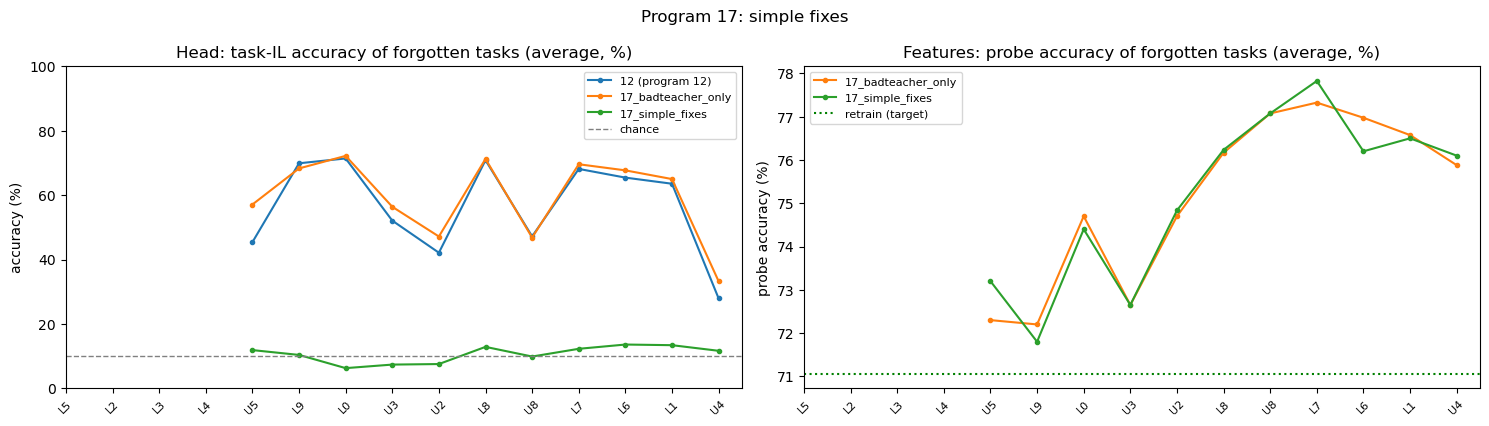

In [4]:
plot_forgotten(runs, "Program 17: simple fixes", "17_simple_fixes.png")

## 5. Each forgotten task separately

For every forgotten task: probe right before its `U`, right after, at the end, and the retrain target for that task. If the features of a task stay far above the retrain target from start to end, the head reset is only *hiding* the task.

In [5]:
for name in RUNS:
    s = results[name]["summary"]["probe"]["per_item"]
    print(name)
    print(f"{'task':>6} {'before U':>9} {'after U':>8} {'end':>6} {'retrain':>8} {'end - retrain':>13}")
    for item, (b, a, e) in s.items():
        rt = RETRAIN_PROBE[int(item)] if RETRAIN_PROBE is not None else np.nan
        print(f"{item:>6} {b*100:8.1f}% {a*100:7.1f}% {e*100:5.1f}% {rt*100:7.1f}% {(e - rt)*100:+12.1f}")
    print()

17_badteacher_only
  task  before U  after U    end  retrain end - retrain
     5     71.2%    72.3%  73.5%    71.6%         +1.9
     3     72.4%    70.1%  70.1%    63.8%         +6.3
     2     83.6%    80.1%  80.0%    77.8%         +2.2
     8     86.2%    82.4%  78.0%    69.6%         +8.4
     4     80.6%    77.8%  77.8%    72.5%         +5.3

17_simple_fixes
  task  before U  after U    end  retrain end - retrain
     5     72.7%    73.2%  75.0%    71.6%         +3.4
     3     73.8%    72.3%  70.8%    63.8%         +7.0
     2     82.9%    79.7%  78.1%    77.8%         +0.3
     8     84.4%    84.0%  78.3%    69.6%         +8.7
     4     81.3%    78.3%  78.3%    72.5%         +5.8



## 6. Log the run

In [6]:
log_run("17_buffer_purge_head_reset", SETTINGS, {name: res["summary"] for name, res in results.items()})
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. Output level: did head reset stop the relapse jump of program 12 (45% → 70% at the next `L`)? What are FA and Relapse now?
2. Did the fixes cost anything on the kept tasks (RA, Spill)?
3. Feature level: after `U`, did the probe on forgotten tasks drop at all? Does it rise later? How far is it from the retrain target at the end?
4. The roadmap expected "probe accuracy still rises during later learning". Is that what happened? If not, what does the probe do instead?
5. Given these numbers, what is left for the guard (program 18) to fix?